# 1. Load Final Modeling Dataset

This section loads the final business-level feature dataset created after data cleaning, EDA, and feature engineering.

The target variable is `checkin_count_log`, which represents log-transformed customer check-in activity.

In [0]:
%pip install xgboost

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 69.5 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
from pyspark.sql import functions as F

OUTPUT_PATH = "/Volumes/workspace/default/yelp/features/business_features.parquet"

df_model = spark.read.parquet(OUTPUT_PATH)

print(f"Rows: {df_model.count():,}")
print(f"Columns: {len(df_model.columns)}")

display(df_model.limit(5))

Rows: 52,286
Columns: 42


business_id,is_open,business_avg_stars,checkin_count,checkin_count_log,review_count,avg_stars,avg_review_length,sum_useful,sum_funny,sum_cool,review_count_log,avg_sentiment,positive_ratio,negative_ratio,has_attributes,delivery,takeout,outdoor,credit_cards,good_for_kids,price_range,price_missing,delivery_missing,takeout_missing,has_hours,hours_total_week,hours_weekend,categories,n_categories,is_restaurant,is_food,latitude,longitude,state,city,coord_missing,nearby_business_density,peak_hour_ratio,weekend_ratio,monthly_activity,sentiment_missing
LTTRaIO-p4zjvXtw9zm1Wg,0,4.0,82,4.418840607796598,101,3.8613861386138613,838.4158415841584,408,170,263,4.624972813284271,0.801571287128713,0.9405940594059405,0.0594059405940594,1,0,1,1,1,1,2,0,0,0,1,31.0,16.0,"Restaurants, Cuban, Puerto Rican, Caribbean, Dominican, Latin American",6,1,0,38.638548,-90.2366249,MO,Saint Louis,0,27,0.2926829268292683,0.45121951219512196,3.9047619047619047,0
_Dr8Bnt8us2qyPKayfj-rA,1,2.5,66,4.204692619390966,30,2.566666666666667,586.9666666666667,14,11,9,3.4339872044851463,0.4321966666666667,0.7666666666666667,0.23333333333333334,1,1,1,0,1,1,1,0,0,0,1,88.0,22.0,"American (Traditional), Restaurants, American (New), Breakfast & Brunch, Burgers",5,1,0,28.22827,-82.73109,FL,NEW PORT RICHEY,0,9,0.16666666666666666,0.3939393939393939,1.8857142857142857,0
jz-A6Gq1pM-esuAEKqqSqQ,1,3.5,22,3.1354942159291497,26,3.4615384615384617,418.1923076923077,13,5,1,3.295836866004329,0.4968423076923077,0.8076923076923077,0.15384615384615385,1,0,1,-1,1,1,1,0,0,0,1,93.0,27.0,"Fast Food, Restaurants, Chicken Wings",3,1,1,38.4403418,-90.3734194,MO,Arnold,0,9,0.5454545454545454,0.36363636363636365,1.375,0
pCpHrr2sUS58szoseyF2-w,1,2.5,27,3.332204510175204,29,2.3448275862068964,498.2068965517241,3,3,1,3.4011973816621555,-0.016331034482758612,0.5172413793103449,0.4482758620689655,1,1,1,-1,1,-1,1,0,0,0,1,0.0,0.0,"Food, Bakeries, Donuts, Restaurants, Coffee & Tea",5,1,1,39.7175199073,-75.1129314706,NJ,Glassboro,0,17,0.2962962962962963,0.25925925925925924,1.9285714285714286,0
A3Qt87F7ZaAwCW4CyyB1Fw,1,4.5,218,5.389071729816501,213,4.286384976525822,453.92957746478874,319,117,194,5.365976015021851,0.7630173708920187,0.92018779342723,0.07042253521126761,1,0,1,0,1,1,1,0,0,0,1,49.0,14.0,"Restaurants, Food, Vegan, Cafes, Donuts",5,1,1,39.9483447,-75.2136558,PA,Philadelphia,0,49,0.46788990825688076,0.5137614678899083,3.6333333333333333,0


# 2. Select Target and Feature Columns

The target variable is separated from predictor variables.

Identifier columns and non-numeric variables are excluded from model training.

In [0]:
target_col = "checkin_count_log"

exclude_cols = [
    "business_id",
    "checkin_count",
    "checkin_count_log",
    "categories",
    "city",
    "state",
    "latitude",
    "longitude",
    "lat_grid",
    "lng_grid"
]

feature_cols = [
    c for c, t in df_model.dtypes
    if c not in exclude_cols and t in ["int", "bigint", "double", "float"]
]

print("Target column:", target_col)
print("Number of feature columns:", len(feature_cols))
print(feature_cols)

Target column: checkin_count_log
Number of feature columns: 34
['is_open', 'business_avg_stars', 'review_count', 'avg_stars', 'avg_review_length', 'sum_useful', 'sum_funny', 'sum_cool', 'review_count_log', 'avg_sentiment', 'positive_ratio', 'negative_ratio', 'has_attributes', 'delivery', 'takeout', 'outdoor', 'credit_cards', 'good_for_kids', 'price_range', 'price_missing', 'delivery_missing', 'takeout_missing', 'has_hours', 'hours_total_week', 'hours_weekend', 'n_categories', 'is_restaurant', 'is_food', 'coord_missing', 'nearby_business_density', 'peak_hour_ratio', 'weekend_ratio', 'monthly_activity', 'sentiment_missing']


# 3. Convert Spark DataFrame to Pandas

XGBoost and LightGBM are applied using Python machine learning libraries.

The final feature table is converted from Spark DataFrame to Pandas DataFrame after aggregation.

In [0]:
model_pdf = (
    df_model
    .select(["business_id", target_col] + feature_cols)
    .dropna(subset=[target_col])
    .toPandas()
)

print(model_pdf.shape)

model_pdf.head()

(52286, 36)


,business_id,checkin_count_log,is_open,business_avg_stars,review_count,avg_stars,avg_review_length,sum_useful,sum_funny,sum_cool,review_count_log,avg_sentiment,positive_ratio,negative_ratio,has_attributes,delivery,takeout,outdoor,credit_cards,good_for_kids,price_range,price_missing,delivery_missing,takeout_missing,has_hours,hours_total_week,hours_weekend,n_categories,is_restaurant,is_food,coord_missing,nearby_business_density,peak_hour_ratio,weekend_ratio,monthly_activity,sentiment_missing
0,LTTRaIO-p4zjvXtw9zm1Wg,4.418841,0,4.0,101,3.861386,838.415842,408,170,263,4.624973,0.801571,0.940594,0.059406,1,0,1,1,1,1,2,0,0,0,1,31.0,16.0,6,1,0,0,27,0.292683,0.451220,3.904762,0
1,_Dr8Bnt8us2qyPKayfj-rA,4.204693,1,2.5,30,2.566667,586.966667,14,11,9,3.433987,0.432197,0.766667,0.233333,1,1,1,0,1,1,1,0,0,0,1,88.0,22.0,5,1,0,0,9,0.166667,0.393939,1.885714,0
2,jz-A6Gq1pM-esuAEKqqSqQ,3.135494,1,3.5,26,3.461538,418.192308,13,5,1,3.295837,0.496842,0.807692,0.153846,1,0,1,-1,1,1,1,0,0,0,1,93.0,27.0,3,1,1,0,9,0.545455,0.363636,1.375000,0
3,pCpHrr2sUS58szoseyF2-w,3.332205,1,2.5,29,2.344828,498.206897,3,3,1,3.401197,-0.016331,0.517241,0.448276,1,1,1,-1,1,-1,1,0,0,0,1,0.0,0.0,5,1,1,0,17,0.296296,0.259259,1.928571,0
4,A3Qt87F7ZaAwCW4CyyB1Fw,5.389072,1,4.5,213,4.286385,453.929577,319,117,194,5.365976,0.763017,0.920188,0.070423,1,0,1,0,1,1,1,0,0,0,1,49.0,14.0,5,1,1,0,49,0.467890,0.513761,3.633333,0


# 4. Train-Test Split

The dataset is divided into training and testing subsets.

- 80% training data
- 20% testing data

A fixed random seed is used for reproducibility.

In [0]:
from sklearn.model_selection import train_test_split

X = model_pdf[feature_cols]
y = model_pdf[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (41828, 34)
X_test: (10458, 34)


# 5. Model Evaluation Function

Model performance is evaluated using:

- RMSE
- MAE
- R²

In [0]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

def evaluate_model(model_name, y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

# 6. Baseline Model - Liner Regression

Linear Regression is used as the baseline model.

In [0]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_result = evaluate_model(
    "Linear Regression",
    y_test,
    lr_pred
)

lr_result

{'Model': 'Linear Regression',
 'RMSE': np.float64(0.7465768428090633),
 'MAE': 0.5738653603071404,
 'R2': 0.7930725245998924}

## *Optional Ensemble Benchmark - Random Forest*

Random Forest was additionally evaluated as an optional ensemble benchmark model to compare its predictive performance against boosting-based approaches such as XGBoost and LightGBM. Random Forest is a tree-based ensemble learning algorithm that reduces overfitting by aggregating multiple decision trees through bootstrap sampling and feature randomness.

In [0]:
# Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_result = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

rf_result

{'Model': 'Random Forest',
 'RMSE': np.float64(0.43827190189843107),
 'MAE': 0.33344225384911474,
 'R2': 0.9286890230532742}

# 7. XGBoost Regression Model

XGBoost is applied as an ensemble gradient boosting model.

In [0]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_result = evaluate_model(
    "XGBoost",
    y_test,
    xgb_pred
)

xgb_result

{'Model': 'XGBoost',
 'RMSE': np.float64(0.4150857366855687),
 'MAE': 0.3206043320191399,
 'R2': 0.9360346545188669}

# 8. LightGBM Regression Model

LightGBM is applied as another ensemble gradient boosting model.

In [0]:
from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_test)

lgbm_result = evaluate_model(
    "LightGBM",
    y_test,
    lgbm_pred
)

lgbm_result

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003210 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3856
[LightGBM] [Info] Number of data points in the train set: 41828, number of used features: 31
[LightGBM] [Info] Start training from score 3.816305


{'Model': 'LightGBM',
 'RMSE': np.float64(0.40963857317461844),
 'MAE': 0.3170025911768851,
 'R2': 0.9377024712931052}

# 9. Model Performance Evaluation

The models are compared using RMSE, MAE, and R².

In [0]:
results_df = pd.DataFrame([
    lr_result,
    rf_result,
    xgb_result,
    lgbm_result
])

results_df = results_df.sort_values(
    "RMSE"
)

display(
    results_df.style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}",
        "R2": "{:.2%}"
    })
)

,Model,RMSE,MAE,R2
3,LightGBM,0.4096,0.3170,93.77%
2,XGBoost,0.4151,0.3206,93.60%
1,Random Forest,0.4383,0.3334,92.87%
0,Linear Regression,0.7466,0.5739,79.31%


## 9.1 Classification Performance
In addition to regression evaluation, classification performance was assessed as a robustness check.
The continuous check-in demand target was converted into a binary demand class using the 75th percentile of the training target as the high-demand threshold. Businesses above this threshold were labeled as high-demand, while the remaining businesses were labeled as low/medium-demand.

Accuracy, precision, recall, and F1-score were calculated to evaluate how well the regression-based predictions could distinguish high-demand businesses.

classification performance was additionally evaluated as a robustness 
- Accuracy
- Precision
- Recall
- F1-score

F1-score was considered more important than accuracy because the high-demand business class was relatively imbalanced. Therefore, evaluating both precision and recall together provided a more reliable assessment of model performance.

## Optional SVM Classification Benchmark
Support Vector Machine (SVM) was additionally evaluated as a traditional machine learning classification benchmark to compare its performance against ensemble boosting approaches. SVM is widely used for classification tasks due to its ability to identify optimal decision boundaries between classes.

In [0]:
# Optional SVM Classification Benchmark

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# High-demand threshold
demand_threshold = y_train.quantile(0.75)

# Binary classification labels
y_train_class = (y_train >= demand_threshold).astype(int)
y_test_class = (y_test >= demand_threshold).astype(int)

# SVM pipeline with feature scaling
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

# Train SVM classifier
svm_model.fit(X_train, y_train_class)

# Predict classification labels
svm_pred = svm_model.predict(X_test)

# Evaluate SVM classification performance
svm_results = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test_class, svm_pred),
    "Precision": precision_score(y_test_class, svm_pred, zero_division=0),
    "Recall": recall_score(y_test_class, svm_pred, zero_division=0),
    "F1-score": f1_score(y_test_class, svm_pred, zero_division=0)
}

print(svm_results)

{'Model': 'SVM', 'Accuracy': 0.9304838401223944, 'Precision': 0.8873297565002064, 'Recall': 0.825652841781874, 'F1-score': 0.8553809429082952}


In [0]:
# Convert regression predictions into demand classes

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use 75th percentile of training target as high-demand threshold
demand_threshold = y_train.quantile(0.75)

print("High-demand threshold:", demand_threshold)

# Actual class
y_test_class = (y_test >= demand_threshold).astype(int)

# Predicted classes from each regression model
lr_class = (lr_pred >= demand_threshold).astype(int)
xgb_class = (xgb_pred >= demand_threshold).astype(int)
lgbm_class = (lgbm_pred >= demand_threshold).astype(int)

def evaluate_classification(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

classification_results = pd.DataFrame([
    evaluate_classification("Linear Regression", y_test_class, lr_class),
    evaluate_classification("XGBoost", y_test_class, xgb_class),
    evaluate_classification("LightGBM", y_test_class, lgbm_class),
    svm_results
])

classification_results = classification_results.sort_values(
    "F1-score",
    ascending=False
)

display(
    classification_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

High-demand threshold: 5.003946305945459


,Model,Accuracy,Precision,Recall,F1-score
2,LightGBM,93.57%,88.80%,84.91%,86.81%
1,XGBoost,93.56%,88.98%,84.64%,86.75%
3,SVM,93.05%,88.73%,82.57%,85.54%
0,Linear Regression,90.51%,86.44%,73.43%,79.40%


## Classification Performance as a Robustness Check

The classification results indicate that the ensemble-based and kernel-based machine learning models achieved strong predictive performance in distinguishing high-demand businesses from low- and medium-demand businesses.

LightGBM achieved the highest overall performance with an accuracy of 93.57%, precision of 88.80%, recall of 84.91%, and F1-score of 86.81%. XGBoost produced highly comparable results, achieving an accuracy of 93.56% and an F1-score of 86.75%. SVM also demonstrated strong classification capability, achieving an accuracy of 93.05% and an F1-score of 85.54%.

Compared with the advanced machine learning models, Linear Regression showed relatively lower classification performance, with an accuracy of 90.51% and an F1-score of 79.40%. These findings suggest that non-linear machine learning models were more effective for identifying high-demand businesses than the baseline linear model.

Overall, the classification evaluation supports the robustness of the predictive framework and demonstrates that Yelp-derived features can effectively distinguish businesses with high customer demand.


### 9.2 Confusion Matrix
- Confustion matrix figure
- classfication report

The classification report and confusion matrix indicate that the LightGBM model achieved strong predictive performance for both low-/medium-demand and high-demand businesses. In particular, the model achieved an F1-score of 0.87 for the high-demand class, demonstrating effective identification of businesses with high customer demand.

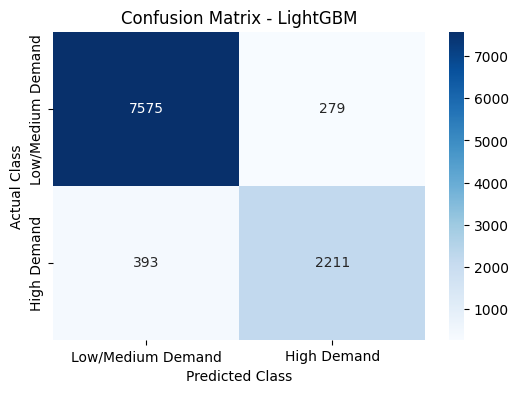

                   precision    recall  f1-score   support

Low/Medium Demand       0.95      0.96      0.96      7854
      High Demand       0.89      0.85      0.87      2604

         accuracy                           0.94     10458
        macro avg       0.92      0.91      0.91     10458
     weighted avg       0.94      0.94      0.94     10458



In [0]:
# Confusion Matrix for the best classification result

best_class_model = classification_results.iloc[0]["Model"]

if best_class_model == "XGBoost":
    best_class_pred = xgb_class
elif best_class_model == "LightGBM":
    best_class_pred = lgbm_class
else:
    best_class_pred = lr_class

cm = confusion_matrix(y_test_class, best_class_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low/Medium Demand", "High Demand"],
    yticklabels=["Low/Medium Demand", "High Demand"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(f"Confusion Matrix - {best_class_model}")
plt.show()

print(classification_report(
    y_test_class,
    best_class_pred,
    target_names=["Low/Medium Demand", "High Demand"]
))

The high-demand class was considered particularly important because identifying businesses with strong customer demand is more valuable for business intelligence and location-based decision-making than identifying low-demand businesses.

# 10. Actual vs Predicted Results

This section compares actual and predicted demand values from the best-performing model.

In [0]:
best_model_name = results_df.iloc[0]["Model"]

if best_model_name == "XGBoost":

    best_pred = xgb_pred

elif best_model_name == "LightGBM":

    best_pred = lgbm_pred

else:

    best_pred = lr_pred

pred_compare = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_pred
})

display(pred_compare.head(20))

Actual,Predicted
4.48863636973214,4.43503326493966
5.484796933490655,5.4895341188090505
5.0369526024136295,5.064665517675743
4.844187086458591,4.120696907337083
8.00202481821611,7.829579317844897
3.4965075614664802,3.859232565547795
5.8522024797744745,5.712659696635007
2.995732273553991,3.5309480364891948
4.844187086458591,4.5827923818256755
3.8501476017100584,4.137728270702051


# 11. Feature Importance

Feature importance is used to identify which variables contribute most strongly to business demand prediction.

In [0]:
if best_model_name == "XGBoost":

    importance_values = xgb_model.feature_importances_

elif best_model_name == "LightGBM":

    importance_values = lgbm_model.feature_importances_

else:

    importance_values = abs(lr_model.coef_)

feature_importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance_df.head(20))

Feature,Importance
monthly_activity,1561
weekend_ratio,1069
peak_hour_ratio,1011
review_count,705
avg_stars,393
avg_review_length,343
sum_useful,318
good_for_kids,299
price_range,296
sum_funny,296
